In [1]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.quinex_visualisation import QuinexVisualisation
from quinex_application.metadata_visualisation import VisualisationMetadata

In [2]:
visualisation = QuinexVisualisation()
metadata = VisualisationMetadata("../data/quinex/df_quinex_metadata.parquet")

# **Load Data**

In [3]:
df_paper = visualisation.load_df("../data/paper/paper_dataset.parquet")
df_paper = df_paper[df_paper["Quinex"] == True]

📂 Loaded DataFrame from '../data/paper/paper_dataset.parquet' with 81073 rows


In [4]:
metadata_df = visualisation.load_df("../data/quinex/df_quinex_metadata.parquet")
quinex_df = visualisation.load_df("../data/visualisation_files/df_technologies_nan.parquet")

📂 Loaded DataFrame from '../data/quinex/df_quinex_metadata.parquet' with 31653 rows
📂 Loaded DataFrame from '../data/visualisation_files/df_technologies_nan.parquet' with 3244165 rows


In [ ]:
metadata_df = metadata.add_sjr_to_metadata(
    metadata_df,
    sjr_folder="../data/paper/impactfactor",
    source_col="source",
    year_col="publication_year",
    #source_rename_dict=source_rename_dict
)

metadata_df = metadata_df.merge(
    df_paper[['DOI', 'Source title']],
    on='DOI',
    how='left'
)

mask = metadata_df['SJR'].isna()
metadata_fallback = metadata_df.loc[mask].copy()
metadata_fallback = metadata.add_sjr_to_metadata(
    metadata_fallback,
    sjr_folder="../data/paper/impactfactor",
    source_col="Source title",
    year_col="publication_year",
)
metadata_df.loc[mask, 'SJR'] = metadata_fallback['SJR'].values
metadata_df.to_parquet("../data/quinex/df_quinex_metadata.parquet")

# **Analysis Metadata**

In [ ]:
fig, piv_entity, piv_property = metadata.mention_trend_heatmap(quinex_df[quinex_df["publication_year"] < 2026], "entity_base_mapping", "property_base_mapping", figsize=(24,6), font_size=30, top_n=6, cmap="Blues")
fig.savefig("../data/figures/metadata/ent_prop_distribution.pdf", bbox_inches='tight')

Missing country info: 6091 papers (19.26 %)
Missing SJR info: 6135 papers (19.39 %)


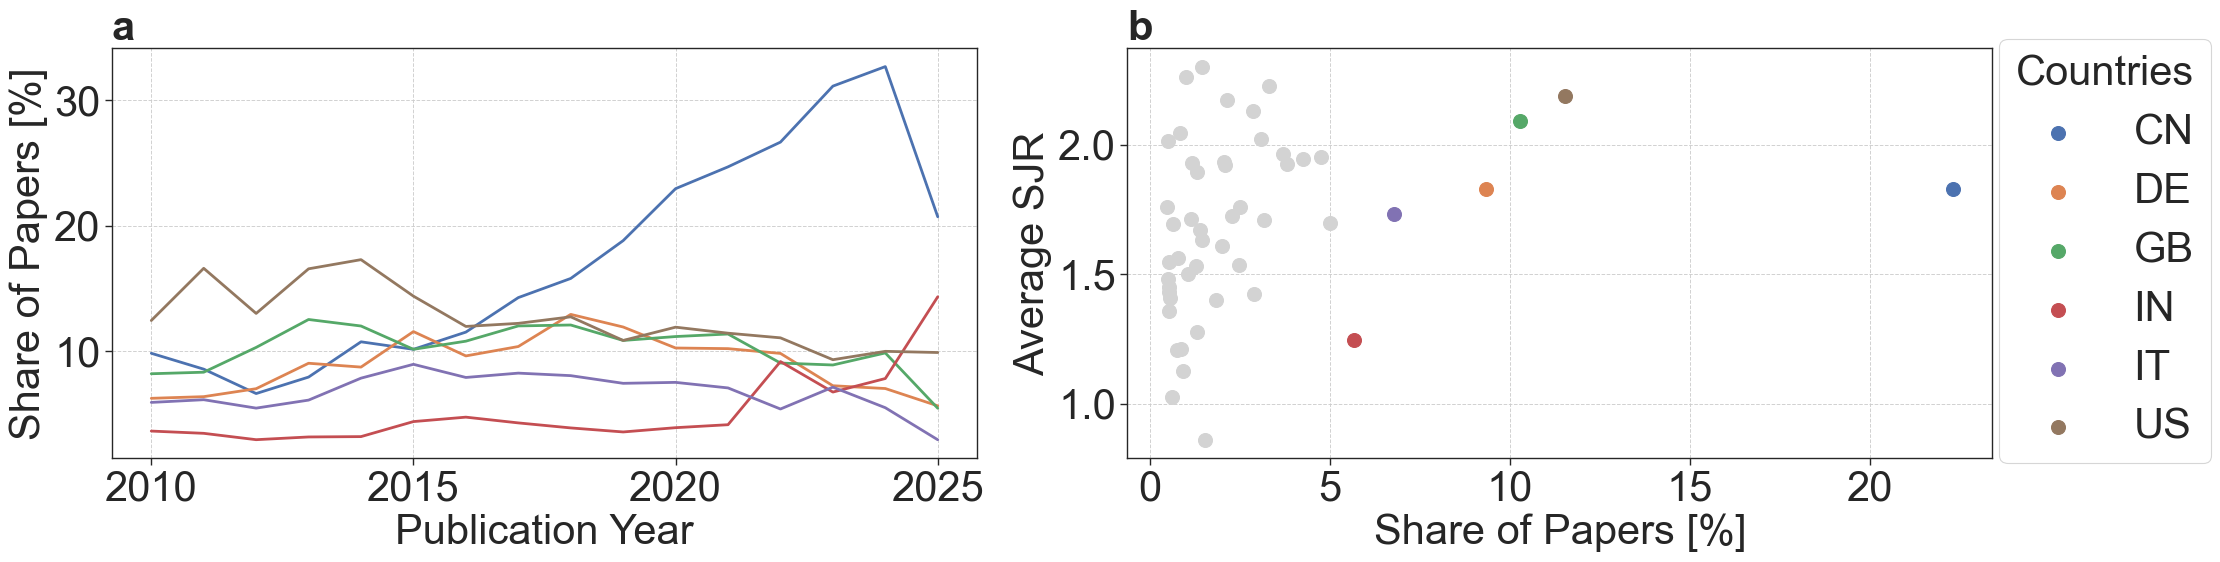

In [38]:
fig, pivot_countries, avg_sjr = metadata.countries_share_and_sjr(metadata_df, top_n_line = 6, top_n_scatter = 50, figsize = (24, 6), font_size=30, legend_bbox=(0.885,0.55))
#fig.savefig("../data/figures/metadata/share_top_countries.pdf", bbox_inches='tight')

In [5]:
country = "CN"
# Filter für Publikationen mit China
pubs = metadata_df[metadata_df['countries'].apply(lambda x: country in x)]

# Liste der DOIs
dois = pubs['DOI'].tolist()
df_china = quinex_df[quinex_df['DOI'].isin(dois)]

In [14]:
country = "JP"
# Filter für Publikationen mit China
pubs = metadata_df[metadata_df['countries'].apply(lambda x: country in x)]

# Liste der DOIs
dois = pubs['DOI'].tolist()
df_japan = quinex_df[quinex_df['DOI'].isin(dois)]

In [30]:
country = "DE"
# Filter für Publikationen mit China
pubs = metadata_df[metadata_df['countries'].apply(lambda x: country in x)]

# Liste der DOIs
dois = pubs['DOI'].tolist()
df_germany = quinex_df[quinex_df['DOI'].isin(dois)]

In [ ]:
country = "GB"
# Filter für Publikationen mit China
pubs = metadata_df[metadata_df['countries'].apply(lambda x: country in x)]

# Liste der DOIs
dois = pubs['DOI'].tolist()
df_gb = quinex_df[quinex_df['DOI'].isin(dois)]

In [33]:
country = "NL"
# Filter für Publikationen mit China
pubs = metadata_df[metadata_df['countries'].apply(lambda x: country in x)]

# Liste der DOIs
dois = pubs['DOI'].tolist()
df_netherlands = quinex_df[quinex_df['DOI'].isin(dois)]

In [40]:
country = "IR"
# Filter für Publikationen mit China
pubs = metadata_df[metadata_df['countries'].apply(lambda x: country in x)]

# Liste der DOIs
dois = pubs['DOI'].tolist()
df_iran = quinex_df[quinex_df['DOI'].isin(dois)]

c:\Gorres\Projekte\quinex_application\quinex_application\metadata_visualisation.py:302: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


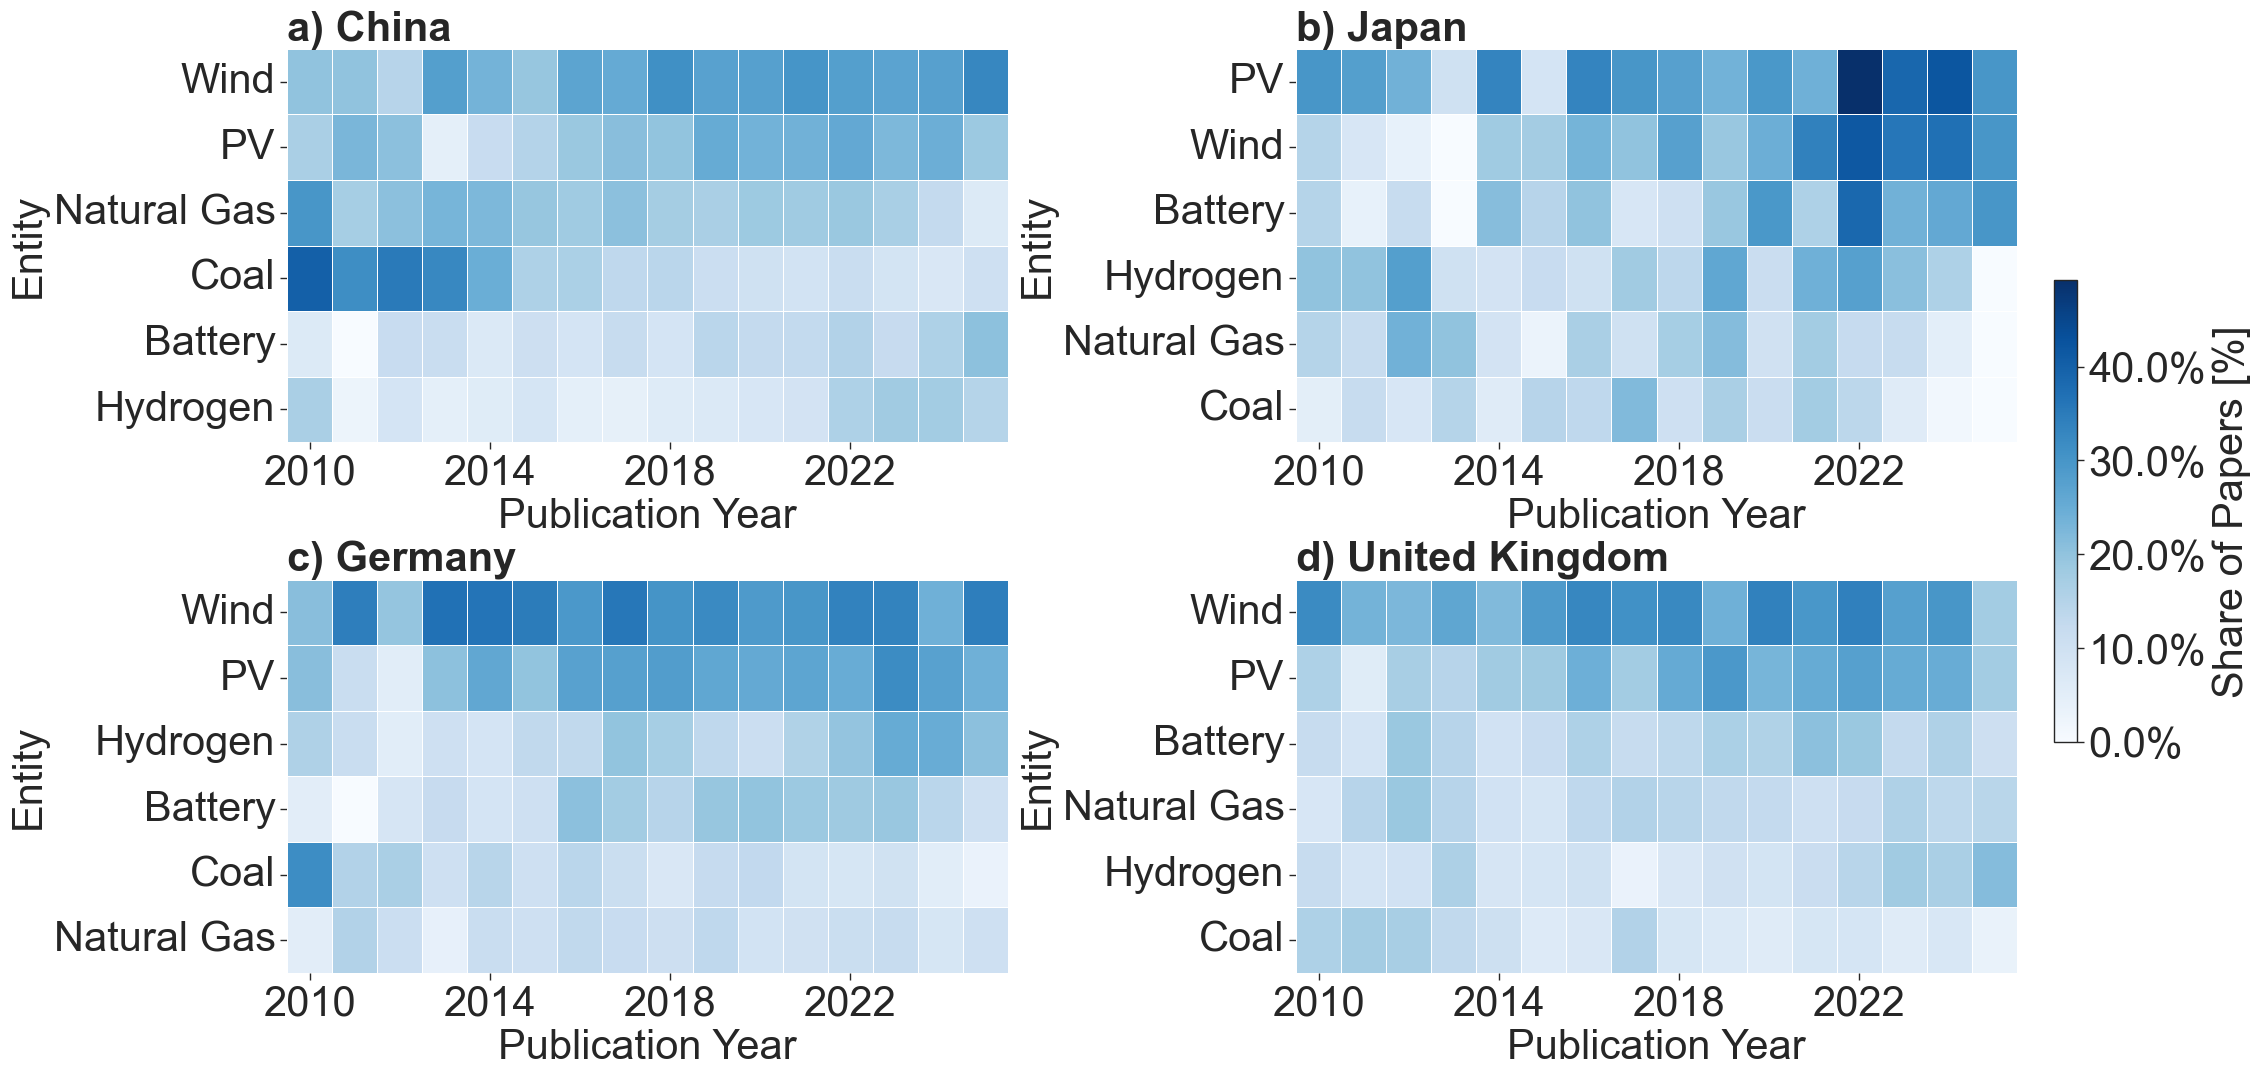

In [42]:
fig, piv_entity = metadata.mention_trend_heatmap_multi_entities(
    dfs = [df_china, df_japan, df_germany, df_gb] ,
    titles = ["a) China", "b) Japan", "c) Germany", "d) United Kingdom"],
    entity_col = "entity_base_mapping",
    figsize=(24,6),
    font_size=30, 
    top_n=6, 
    cmap="Blues"
    )
#fig.savefig("../data/figures/metadata/ent_spatial_distribution.pdf", bbox_inches='tight')

In [22]:
piv_entity[1]

publication_year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
entity_base_mapping,,,,,,,,,,,,,,,,
PV,0.30,0.28,0.24,0.10,0.333333,0.088235,0.333333,0.30,0.275862,0.238095,0.295082,0.241935,0.492308,0.388060,0.419355,0.3
Wind,0.15,0.08,0.04,0.00,0.181818,0.176471,0.233333,0.20,0.275862,0.190476,0.245902,0.338710,0.415385,0.358209,0.370968,0.3
Battery,0.15,0.04,0.12,0.00,0.212121,0.147059,0.200000,0.08,0.103448,0.190476,0.295082,0.161290,0.384615,0.238806,0.258065,0.3
Hydrogen,0.20,0.20,0.28,0.10,0.090909,0.117647,0.100000,0.18,0.137931,0.261905,0.114754,0.241935,0.276923,0.208955,0.161290,0.0
Natural Gas,0.15,0.12,0.24,0.20,0.090909,0.029412,0.166667,0.10,0.172414,0.214286,0.098361,0.177419,0.123077,0.119403,0.048387,0.0
Coal,0.05,0.12,0.08,0.15,0.060606,0.147059,0.133333,0.22,0.103448,0.166667,0.114754,0.177419,0.138462,0.059701,0.016129,0.0


In [44]:


# 2. Nur Zeilen mit gültigem SJR und CN filtern (optional, falls du nur China willst)
filtered_df = metadata_df[
    (metadata_df['countries'].apply(lambda x: "CN" in x)) 
    #& (metadata_df['SJR'].notna())
]
filtered_df["topics"].value_counts()
# 3. Durchschnitt von SJR pro Jahr berechnen
# avg_sjr_per_year = filtered_df.groupby('publication_year')['SJR'].mean()

# print(avg_sjr_per_year)

topics
[Integrated Energy Systems Optimization]                                                                                                      9
[Power Systems and Renewable Energy]                                                                                                          7
[Smart Grid and Power Systems]                                                                                                                3
[Water-Energy-Food Nexus Studies]                                                                                                             3
[Nuclear and radioactivity studies]                                                                                                           2
                                                                                                                                             ..
[Integrated Energy Systems Optimization, Hybrid Renewable Energy Systems, Building Energy and Comfort Optimization]              

In [ ]:
avg_sjr[avg_sjr["countries"] =="CN"]

In [39]:
avg_sjr[avg_sjr["share_of_paper"] > 0.02].sort_values(by='share_of_paper', ascending=False)

,countries,share_of_paper,average_sjr
8,CN,0.223084,1.828510
47,US,0.115261,2.188296
18,GB,0.102733,2.090756
11,DE,0.093180,1.827572
26,IT,0.067888,1.731656
23,IN,0.056613,1.246864
25,IR,0.049996,1.698613
12,DK,0.047490,1.953734
5,CA,0.042557,1.942839
15,ES,0.038133,1.926182


In [ ]:
# Filter anwenden
df = avg_sjr[avg_sjr["countries"].isin(countries_by_continent["Asia"])]
df["average_sjr"].mean()

In [ ]:
countries_by_continent = {
    "Africa": [
        "MZ","NE","NG","LY","MA","ML","MR","MW","NA","RW","ZA","ZM","TG","TD","BW","CD",
        "CF","CM","CI","DJ","DZ","EG","ET","GH","GM","GN","KE","LS","LR","SN","BJ",
        "MU","MZ","RE","SC","SD","SL","SO","SS","SZ","TZ","TN","UG","ZW",'BI',"BF"
    ],
    "Asia": [
        "AF","AM","AZ","BD","BT","BN","KH","CN","IN","ID","IR","IQ","IL","JP","JO",
        "KZ","KW","KG","LA","LB","MY","MV","MN","MM","NP","OM","PK","PS","PH","QA","SA","SG",
        "KR","LK","SY","TW","TJ","TH","TR","AE","UZ","VN","YE","HK","MO","BH","CV"
    ],
    "Europe": [
        "AL","AD","AT","BY","BE","BA","BG","HR","CY","CZ","DK","EE","FO","FI","FR","DE",
        "GR","HU","IS","IE","IT","LV","LT","LU","MK","MT","ME",
        "NL","NO","PL","PT","RO","RU","RS","SK","SI","ES","SE","CH","UA","GB","XK"
    ],
    "North America": [
        "BB","CA","CR","CU","DO","GL","JM","MX","NI","PA","PR","TT","US","GP"
    ],
    "South America": [
        "AR","BO","BR","CL","CO","EC","GF","PE","PY","SR","VE","AW"
    ],
    "Oceania": [
        "AU","FJ","NZ","PG","WS",
    ]
}